# Formulas: the value function, the current model, comfort

- Position $(a, b)$: the side to move has $a$ own words left, the other side $b$.
- Incumbent: `assoc_profile_listener`, the fixed opponent in every win rate.
- Comfort arena: 100 held-out boards × 2 seatings; gpt-oss-120b guesses in two calls
  (the "guess" set $G$ without the number, then a ranking of $G$ with the number; stops at
  a wrong word, after $k$ picks, or when $G$ runs out; never takes $k+1$).
- Data: `cache/win_value_margin.npz`, `cache/report/comfort_frontier_holdout_v1_gptoss_subset_guess.json`.
  No API calls.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("..").resolve()
sys.path[:0] = [str(ROOT), str(ROOT / "scripts" / "data")]
from codenames.win_value import WinValue

D = np.load(ROOT / "cache" / "win_value_margin.npz")
n, w, prior, V = D["n"], D["wins"], D["prior"], D["V"]
val = WinValue(ROOT / "cache" / "win_value_margin.npz")
idx = pd.Index(range(1, 10), name="a \\ b")

def grid(T, fmt="{:.3f}"):
    df = pd.DataFrame(T[1:, 1:], index=idx, columns=range(1, 10))
    return df.style.format(lambda x: "–" if pd.isna(x) else fmt.format(x))

## 1. The value function

$$V(a, b) = P(\text{side to move wins} \mid a, b)$$

From 10,266 incumbent-vs-incumbent games with gpt-oss guessing. One data point per game per
turn-start position: $n_{ab}$ data points, $w_{ab}$ won.

Data points per cell, $n_{ab}$:

In [2]:
print(f"{int(n.sum()):,} data points")
grid(n.astype(float), "{:,.0f}")

86,287 data points


,1,2,3,4,5,6,7,8,9
a \ b,,,,,,,,,
1,"3,886","2,334",941,477,104,26,4,7,0
2,"3,626","3,079","2,005",847,339,84,28,8,0
3,"2,481","3,035","2,631","1,653",649,186,103,14,6
4,"1,255","2,024","2,716","2,216","1,419",641,172,28,13
5,499,"1,194","2,147","2,440","2,049","1,436",370,72,4
6,141,487,"1,235","1,958","2,611","1,903",648,102,0
7,57,171,317,942,"1,847","2,340","1,416",808,130
8,9,31,89,254,"1,327","2,861","3,863",762,194
9,0,13,16,16,91,126,8,"10,266",0


**1. Raw rate**
$$\hat p_{ab} = \frac{w_{ab}}{n_{ab}}$$

In [3]:
grid(np.where(n > 0, w / np.maximum(n, 1), np.nan))

,1,2,3,4,5,6,7,8,9
a \ b,,,,,,,,,
1,0.965,0.991,0.991,0.994,1.000,1.000,1.000,1.000,–
2,0.186,0.791,0.949,0.980,0.988,0.988,0.929,1.000,–
3,0.023,0.360,0.717,0.842,0.920,0.984,0.932,1.000,0.167
4,0.012,0.142,0.376,0.696,0.812,0.850,0.965,1.000,0.615
5,0.016,0.061,0.252,0.453,0.661,0.752,0.830,0.861,1.000
6,0.000,0.049,0.155,0.289,0.452,0.645,0.730,0.863,–
7,0.018,0.018,0.104,0.171,0.311,0.473,0.614,0.679,0.692
8,0.000,0.000,0.067,0.110,0.297,0.398,0.544,0.639,0.639
9,–,0.385,0.312,0.125,0.176,0.476,0.250,0.478,–


**2. Logistic fit**
$$\operatorname{logit} \pi_{ab} = \theta^\top x_{ab}, \qquad
x_{ab} = \left(1,\ a,\ b,\ a^2,\ b^2,\ ab,\ \tfrac{1}{a},\ \tfrac{1}{b}\right)$$
$$\hat\theta = \arg\min_\theta -\sum_{a, b} \Big[ w_{ab} \log \sigma(\theta^\top x_{ab})
+ (n_{ab} - w_{ab}) \log\big(1 - \sigma(\theta^\top x_{ab})\big) \Big]$$

In [4]:
grid(prior)

,1,2,3,4,5,6,7,8,9
a \ b,,,,,,,,,
1,0.961,0.997,0.999,1.000,1.000,1.000,1.000,1.000,1.000
2,0.188,0.786,0.939,0.977,0.989,0.994,0.996,0.997,0.998
3,0.033,0.354,0.697,0.863,0.931,0.961,0.974,0.981,0.984
4,0.011,0.145,0.415,0.661,0.808,0.884,0.922,0.941,0.949
5,0.005,0.068,0.233,0.455,0.643,0.765,0.834,0.872,0.889
6,0.002,0.036,0.136,0.301,0.482,0.627,0.723,0.779,0.806
7,0.001,0.022,0.085,0.203,0.355,0.498,0.606,0.675,0.711
8,0.001,0.014,0.057,0.143,0.264,0.394,0.502,0.576,0.616
9,0.001,0.010,0.041,0.106,0.204,0.316,0.418,0.492,0.534


**3. Shrinkage toward the fit** ($m = 20$ pseudo-games)
$$\tilde V_{ab} = \frac{w_{ab} + m\, \pi_{ab}}{n_{ab} + m}
= (1 - \alpha_{ab})\, \hat p_{ab} + \alpha_{ab}\, \pi_{ab},
\qquad \alpha_{ab} = \frac{m}{n_{ab} + m}$$

Example cells, each step:

In [5]:
shrunk = (w + 20 * prior) / (n + 20)
rows = [{"(a, b)": f"({a}, {b})", "n": int(n[a, b]), "raw": w[a, b] / n[a, b] if n[a, b] else np.nan,
         "fit π": prior[a, b], "α": 20 / (n[a, b] + 20), "shrunk": shrunk[a, b], "V": V[a, b]}
        for a, b in [(9, 8), (4, 4), (8, 8), (8, 9), (8, 2), (9, 2), (3, 9)]]
pd.DataFrame(rows).set_index("(a, b)").style.format(
    {"raw": "{:.3f}", "fit π": "{:.3f}", "α": "{:.1%}", "shrunk": "{:.3f}", "V": "{:.3f}"})

,n,raw,fit π,α,shrunk,V
"(a, b)",,,,,,
"(9, 8)",10266,0.478,0.492,0.2%,0.478,0.478
"(4, 4)",2216,0.696,0.661,0.9%,0.696,0.696
"(8, 8)",762,0.639,0.576,2.6%,0.637,0.631
"(8, 9)",194,0.639,0.616,9.3%,0.637,0.651
"(8, 2)",31,0.000,0.014,39.2%,0.006,0.030
"(9, 2)",13,0.385,0.010,60.6%,0.158,0.028
"(3, 9)",6,0.167,0.984,76.9%,0.795,0.968


**4. Monotone projection with a margin** ($c = 0.5$; weights $n_{ab} + m$; Dykstra)
$$V = \Pi_{\text{monotone}}\big(\tilde V - c\,\pi\big) + c\,\pi, \qquad
V(a+1, b) \le V(a, b),\quad V(a, b+1) \ge V(a, b)$$

Final $V$:

In [6]:
grid(V)

,1,2,3,4,5,6,7,8,9
a \ b,,,,,,,,,
1,0.965,0.991,0.992,0.994,1.000,1.000,1.000,1.000,1.000
2,0.186,0.791,0.949,0.979,0.986,0.988,0.989,0.998,0.998
3,0.024,0.360,0.717,0.842,0.920,0.956,0.963,0.966,0.968
4,0.013,0.142,0.376,0.696,0.812,0.851,0.937,0.946,0.951
5,0.010,0.062,0.252,0.453,0.661,0.752,0.830,0.878,0.908
6,0.005,0.046,0.155,0.289,0.453,0.645,0.730,0.832,0.845
7,0.004,0.034,0.103,0.172,0.324,0.473,0.614,0.681,0.699
8,0.001,0.030,0.078,0.121,0.279,0.403,0.544,0.631,0.651
9,0.001,0.028,0.070,0.103,0.181,0.364,0.415,0.478,0.534


**Value of one own word**
$$\text{one\_word}(a, b) = V(b, a) - V(b, a-1), \qquad 1 - V(b, 0) = 1$$

In [7]:
pts = [(9, 8), (8, 9), (6, 6), (5, 4), (4, 4), (4, 2), (5, 2), (4, 1), (2, 2), (1, 4)]
pd.DataFrame({"one_word": [val.one_word(a, b) for a, b in pts]},
             index=pd.Index([f"({a}, {b})" for a, b in pts], name="(a, b)")).style.format("{:.3f}")

,one_word
"(a, b)",
"(9, 8)",0.020
"(8, 9)",0.064
"(6, 6)",0.193
"(5, 4)",0.116
"(4, 4)",0.320
"(4, 2)",0.031
"(5, 2)",0.006
"(4, 1)",0.002
"(2, 2)",0.605


**Check: fit weighted by $\sqrt{n_{ab}}$ instead of $n_{ab}$.** Fit error is $|\pi_{ab} - \hat p_{ab}|$.

In [8]:
from build_win_value import logistic_fit, monotone_with_margin

def build(pi):
    T = (w + 20 * pi) / (n + 20)
    T[1:, 1:] = monotone_with_margin(T[1:, 1:].copy(), n[1:, 1:] + 20, pi[1:, 1:], 0.5)
    T[0, :], T[:, 0] = 1.0, 0.0
    return T

assert np.allclose(logistic_fit(n, w), prior) and np.allclose(build(prior)[1:, 1:], V[1:, 1:])
s = np.sqrt(n)
prior_sqrt = logistic_fit(np.where(n > 0, s, 0), np.where(n > 0, w / np.maximum(s, 1), 0))
V_sqrt = build(prior_sqrt)
rate = np.where(n > 0, w / np.maximum(n, 1), np.nan)
has = n[1:, 1:] > 0
nn = n[1:, 1:][has]
d = np.abs(V_sqrt - V)[1:, 1:]
out = {}
for name, pi, T in (("weight n (used)", prior, V), ("weight sqrt(n)", prior_sqrt, V_sqrt)):
    err = np.abs(pi - rate)[1:, 1:][has]
    out[name] = {"fit error, game-weighted": np.average(err, weights=nn),
                 "fit error, cells with 20-200 games": err[(nn >= 20) & (nn < 200)].mean(),
                 "opening one_word": T[8, 9] - T[8, 8],
                 "mean |V - V_used|, game-weighted": (np.abs(T - V)[1:, 1:] * n[1:, 1:]).sum() / n.sum()}
pd.DataFrame(out).T.style.format("{:.4f}")

,"fit error, game-weighted","fit error, cells with 20-200 games",opening one_word,"mean |V - V_used|, game-weighted"
weight n (used),0.0165,0.0322,0.0202,0.0000
weight sqrt(n),0.0216,0.0385,0.0103,0.0003


## 2. The current model: `floored_overpromise_listener` (λ = 1, φ = 0.05)

1. Shortlist: Gaussian embedding model, best 200 of ~11,000 clues.
2. STOP listener predicts each pick.
3. $\arg\max$ over clue and $k \le \min(a, 4)$ of $W_k(\varnothing)$.

### STOP listener

$$P(x \mid j) = \frac{e^{s_j(x)}}{\sum_{y \notin F} e^{s_j(y)} + e^{s_j(\text{STOP})}}$$

- $s_j$: LightGBM score; 68 features (the incumbent listener's 67 without $k$, plus $j$ and is-STOP).
- Data: 18,687 generated positions, 250 training words; clues aimed 40% own, 20% opponent,
  10% assassin, 10% neutral, 20% random.
- Labels: gpt-oss "guess" set $S$ (asked without the number), ordered by gpt-oss's ranking.
  Events: pick $j$ → $j$-th word of $S$, $j = 1..|S|$; pick $|S|+1$ → STOP.
- Loss: $L = -\sum_e \log P(t_e \mid j_e)$, early-stopped on validation McFadden $R^2$.
- Validation: $R^2 = 1 - \dfrac{\sum_e -\log P(t_e)}{\sum_e \log |C_e|} = 0.481$
  (picks 1–4: 0.603, 0.430, 0.334, 0.493).

The ranking listener (features and shortlist only), McFadden $R^2$:

In [9]:
acc = pd.read_csv(ROOT / "cache" / "report" / "listener_accuracy.csv")
sets = {"train": "train (in-sample)", "held-out words, generated": "held-out words, gpt-oss",
        "held-out words, generated, Sonnet 5.5": "held-out words, Sonnet 5.5"}
r = acc[(acc.group == "features") & acc.model.isin(["incumbent", "+ association profile"]) & acc.set.isin(sets)]
r = r.assign(set=r.set.map(sets), model=r.model.map({"incumbent": "first listener (Sept.)",
                                                     "+ association profile": "association profile (used)"}))
r.set_index(["set", "model"])[["events", "r2", "pick_1", "pick_2", "pick_3", "pick_4"]].style.format(
    {"r2": "{:.3f}", "pick_1": "{:.3f}", "pick_2": "{:.3f}", "pick_3": "{:.3f}", "pick_4": "{:.3f}"})

### Value of a turn

$\ell = a - |F|$, $j = |F|$:
$$u(\ell, b) = 1 - V(b, \ell), \qquad u(0, b) = 1$$
$$W_k(F) = \begin{cases}
1 & \ell = 0\\[2pt]
u(\ell, b) & j = k\\[2pt]
\displaystyle \sum_{i \in \text{own} \setminus F} P(i \mid j)\, W_k(F \cup \{i\})
+ \sum_{x \in \text{bad}} P(x \mid j)\, u_x(\ell)
+ P(\text{STOP} \mid j)\,\big[u(\ell, b) - c\,(k - j)\big] & \text{otherwise}
\end{cases}$$
$$u_x(\ell) = \begin{cases} u(\ell, b) & \text{neutral} \\ u(\ell, b - 1)\ \ (0 \text{ if } b = 1) & \text{opponent} \\ 0 & \text{assassin} \end{cases}$$

### Overpromise charge (where λ enters)

$$c = \lambda \cdot \max\big(\text{one\_word}(a, b),\ \varphi\big), \qquad \lambda = 1,\ \varphi = 0.05$$

In [10]:
pts = [(9, 8), (8, 9), (6, 6), (4, 4), (4, 2), (5, 2), (4, 1), (2, 2)]
pd.DataFrame([{"(a, b)": f"({a}, {b})", "c, no floor": val.one_word(a, b),
               "c, floor 0.05": max(val.one_word(a, b), 0.05)} for a, b in pts]
             ).set_index("(a, b)").style.format("{:.3f}")

,"c, no floor","c, floor 0.05"
"(a, b)",,
"(9, 8)",0.020,0.050
"(8, 9)",0.064,0.064
"(6, 6)",0.193,0.193
"(4, 4)",0.320,0.320
"(4, 2)",0.031,0.050
"(5, 2)",0.006,0.050
"(4, 1)",0.002,0.050
"(2, 2)",0.605,0.605


## 3. Comfort

$G_t$: the arena guesser's "guess" set for turn $t$ (any colour), number $k_t$; each position counted once.
$$\text{comfort}_t = \frac{\min(|G_t|, k_t)}{k_t}, \qquad
\text{comfort} = \frac{1}{T} \sum_{t=1}^{T} \text{comfort}_t$$

Win rate: share of 200 games against the incumbent. Intervals: 95% bootstrap over boards.

In [11]:
fr = json.loads((ROOT / "cache" / "report" / "comfort_frontier_holdout_v1_gptoss_subset_guess.json").read_text())
tab = pd.DataFrame(fr["rows"])
tab["win% (95% CI)"] = [f"{x:.1%} [{lo:.1%}, {hi:.1%}]" for x, (lo, hi) in zip(tab.win, tab.win_ci)]
tab["comfort (95% CI)"] = [f"{x:.3f} [{lo:.3f}, {hi:.3f}]" for x, (lo, hi) in zip(tab.comfort, tab.comfort_ci)]
front = set(fr.get("frontier", []))
tab["frontier"] = ["*" if i in front or nm in front else "" for i, nm in zip(tab.id, tab.name)]
tab.sort_values("comfort", ascending=False)[["name", "games", "turns", "win% (95% CI)", "comfort (95% CI)", "frontier"]].set_index("name")

,games,turns,win% (95% CI),comfort (95% CI),frontier
name,,,,,
"overpromise 1.0, strict",200,965,"45.5% [40.0%, 51.0%]","0.944 [0.934, 0.954]",*
"overpromise 0.5, strict",200,943,"52.0% [46.5%, 58.0%]","0.929 [0.919, 0.939]",*
"stop, strict",198,912,"47.5% [41.9%, 53.0%]","0.919 [0.907, 0.932]",
"floored margin V + overpromise 1.0, strict",200,934,"51.5% [46.0%, 57.5%]","0.912 [0.898, 0.924]",
"stop_net, strict",200,933,"45.0% [39.0%, 51.5%]","0.910 [0.894, 0.924]",
"margin V + overpromise 1.0, strict",200,938,"51.5% [46.0%, 57.0%]","0.883 [0.866, 0.901]",
"win_prob + overpromise 1.0, strict",200,941,"53.5% [48.5%, 59.0%]","0.873 [0.852, 0.892]",*
profile_temperature,200,942,"50.0% [45.5%, 54.5%]","0.869 [0.854, 0.886]",
"margin V + overpromise 0.5, strict",200,930,"51.0% [45.5%, 56.5%]","0.854 [0.832, 0.875]",


Win rate against comfort (red: floored, green: unfloored, orange: incumbent):

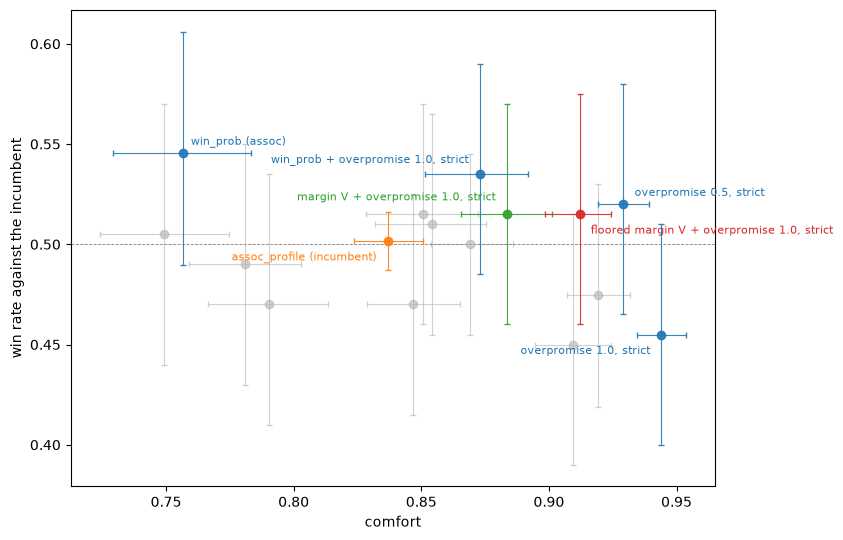

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
LABEL = {  # name: (colour, label offset in points, alignment)
    "floored margin V + overpromise 1.0, strict": ("C3", (8, -14), "left"),
    "margin V + overpromise 1.0, strict": ("C2", (-8, 10), "right"),
    "assoc_profile (incumbent)": ("C1", (-8, -14), "right"),
    "win_prob (assoc)": ("C0", (6, 6), "left"),
    "win_prob + overpromise 1.0, strict": ("C0", (-8, 8), "right"),
    "overpromise 0.5, strict": ("C0", (8, 6), "left"),
    "overpromise 1.0, strict": ("C0", (-8, -14), "right"),
}
for _, r in tab.iterrows():
    colour, off, ha = LABEL.get(r["name"], ("0.7", None, None))
    ax.errorbar(r.comfort, r.win, xerr=[[r.comfort - r.comfort_ci[0]], [r.comfort_ci[1] - r.comfort]],
                yerr=[[r.win - r.win_ci[0]], [r.win_ci[1] - r.win]], fmt="o", ms=6, color=colour,
                alpha=0.9 if off else 0.6, capsize=2, lw=0.8, zorder=3 if off else 2)
    if off:
        ax.annotate(r["name"], (r.comfort, r.win), fontsize=8, xytext=off, textcoords="offset points", ha=ha,
                    color=colour)
ax.axhline(0.5, color="grey", lw=0.6, ls="--")
ax.set_xlabel("comfort")
ax.set_ylabel("win rate against the incumbent")
plt.tight_layout()